# ATP tennis network: Tasks 5 and 6
## Lazy random walk and PageRank

This notebook extends the group's Tasks 1-4, using **all 1,191 players** and the
original completed transition matrix saved in `data/matrices.npz`. An arrow
points from a player who lost to the player who beat them; repeat wins in the
same direction count once. The data cover 2016-2025 and have 19,986 arrows.

**Run all cells from a fresh kernel.** Open this notebook from the repository
root, select `conda_env`, and run top to bottom. Required packages: NumPy,
Matplotlib, and IPython/ipykernel. The scripts in `src/` are imported, so keep
the full repository together. No internet or absolute user paths are needed.

We implement the matrix formulas ourselves and reuse `task3.power_iteration`
through `run_from_starting_players`. No ready-made PageRank is used.



In [1]:
from pathlib import Path
import sys
import csv
import numpy as np
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'src' / 'task3.py').exists():
    if (ROOT.parent / 'src' / 'task3.py').exists():
        ROOT = ROOT.parent
    else:
        raise FileNotFoundError('Open the notebook inside the full project folder.')
sys.path.insert(0, str(ROOT / 'src'))
from task3 import (load_network, run_from_starting_players, plot_player_probabilities,
                   STARTING_PLAYERS, TOLERANCE, MAX_ITERATIONS)
from task4 import print_graph_evidence
from task5 import (lazy_transition, require_convergence, stationary_residual,
                   print_model_summary, plot_model_convergence, print_worked_row)
from task6 import pagerank_transition, ranked_indices, save_scores, plot_rankings

FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
A, P, player_ids = load_network(ROOT / 'data')
names_by_id = {i: name for name, i in player_ids.items()}
n = len(P)
assert n == 1191 and A.sum() == 19986
P_before = P.copy()
print('NumPy:', np.__version__)
print('Players:', n, '| arrows:', int(A.sum()))
print('Starts:', STARTING_PLAYERS)
print('Stopping criterion:', TOLERANCE, '| maximum updates:', MAX_ITERATIONS)

NumPy: 2.5.4
Players: 1191 | arrows: 19986
Starts: ('Novak Djokovic', 'Rohan Bopanna')
Stopping criterion: 1e-10 | maximum updates: 5000


## Same baseline and initial distributions

The row vector $x_k$ is updated by $x_{k+1}=x_kM$. We stop when
$\|x_{k+1}-x_k\|_1<10^{-10}$, with a cap of 5,000 updates. The first change
below the threshold determines the update count. This bounds a successive
change, not automatically the exact error to a stationary vector.

As in Task 3 we start with a point mass at **Novak Djokovic (ID 130)** and
at **Rohan Bopanna (ID 8)**. Djokovic initially follows his 51 outgoing match
arrows. Bopanna is dangling in the original adjacency graph; his completed
row of $P$ is uniform. We do not replace the original completed $P$ with the
lazy matrix when constructing PageRank.

In [2]:
original_runs = run_from_starting_players(P, player_ids)
require_convergence(original_runs)
print_model_summary('Original completed P', P, original_runs)
print_graph_evidence(A, P, player_ids)


Original completed P
Row sums equal one: True
Minimum matrix entry: 0.000000000e+00
  Novak Djokovic: 28 updates; converged=True
    last L1 change=6.628107e-11; stationary residual=3.122094e-11
  Rohan Bopanna: 33 updates; converged=True
    last L1 change=7.304597e-11; stationary residual=3.437235e-11
  Final vectors' L1 gap: 7.796960e-11



Djokovic reaches 1191/1191 players in P.
1191/1191 players can reach Djokovic in P.
2-step return: Novak Djokovic -> Rafael Nadal -> Novak Djokovic
3-step return: Novak Djokovic -> Alexander Zverev -> Roger Federer -> Novak Djokovic
One closed class in P contains every player, so the stationary distribution is unique.
The 2- and 3-step returns have gcd 1, so every starting distribution converges.


## Task 5: construct the lazy walk

For $\beta=0.5$,
$$L=P_{0.5}=0.5P+0.5I.$$
Both terms have nonnegative entries, and row $i$ sums to
$0.5\sum_jP_{ij}+0.5\sum_j I_{ij}=0.5+0.5=1$.
Operationally, flip a fair coin: stay put on one outcome; otherwise follow
the original completed transition. The full stay probability is
$L_{ii}=0.5+0.5P_{ii}$, since the original transition might itself stay put.

In [3]:
L = lazy_transition(P, beta=0.5)
assert np.array_equal(P, P_before), 'Constructing L must not change P.'
assert np.all(L >= 0)
np.testing.assert_allclose(L.sum(axis=1), 1, atol=1e-12, rtol=0)
print_worked_row(A, P, L, player_ids)
# Check every nonzero in the same Task 1 worked row, not just one destination.
i = player_ids['Martin Damm']
destinations = np.flatnonzero(L[i])
print('Nonzero entries in Damm row (node ID, player, P, L):')
for j in destinations:
    print(j, names_by_id[j], f'{P[i,j]:.6f}', f'{L[i,j]:.6f}')
assert A[i].sum() == 2 and P[i,i] == 0
assert L[i, i] == 0.5
np.testing.assert_allclose(L[i, np.flatnonzero(A[i])], 0.25)


Worked row: Martin Damm, ID 1; out-degree=2
Each outgoing arrow: P[i,j]=1/2; lazy P[i,j]=1/4
P[i,i]=0.000000000; lazy P[i,i]=0.500000000
In general the stay probability is 0.5+0.5*P[i,i], not always exactly 0.5.
Destination ID 411: 0.500000000 -> 0.250000000
Lazy row sum: 1.000000000000
Nonzero entries in Damm row (node ID, player, P, L):
1 Martin Damm 0.000000 0.500000
411 Christopher Oconnell 0.500000 0.250000
589 Frances Tiafoe 0.500000 0.250000


### Same worked row as Task 1

Martin Damm (ID 1) has arrows to Christopher O'Connell (ID 411) and
Frances Tiafoe (ID 589). Task 1 gives each destination $1/2$ and all other
entries zero. The lazy row instead has
$$L_{1,1}=1/2,\qquad L_{1,411}=L_{1,589}=1/4.$$
Its sum is $1/2+1/4+1/4=1$: half the time he stays, and half the time he
follows the original two-way choice.


Lazy P_0.5
Row sums equal one: True
Minimum matrix entry: 0.000000000e+00
  Novak Djokovic: 64 updates; converged=True
    last L1 change=8.750861e-11; stationary residual=6.437173e-11
  Rohan Bopanna: 77 updates; converged=True
    last L1 change=7.956350e-11; stationary residual=5.838437e-11
  Final vectors' L1 gap: 3.223313e-10


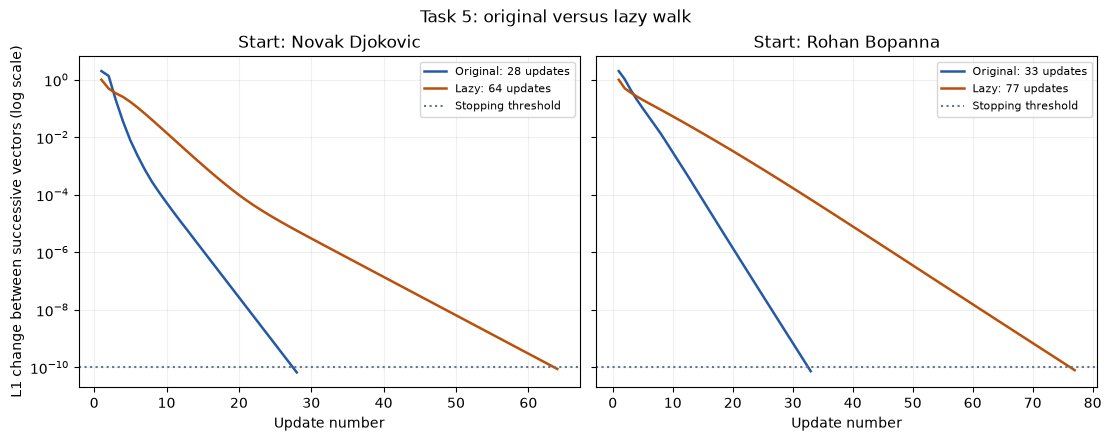

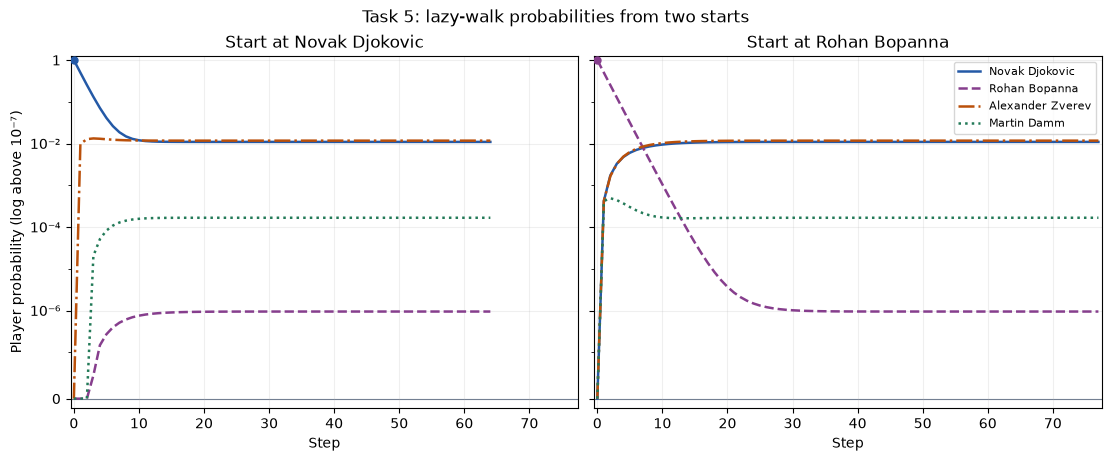

In [4]:
lazy_runs = run_from_starting_players(L, player_ids)
require_convergence(lazy_runs)
print_model_summary('Lazy P_0.5', L, lazy_runs)
fig = plot_model_convergence({'Original': original_runs, 'Lazy': lazy_runs},
                             'Task 5: original versus lazy walk')
fig.savefig(FIGURES / 'task5_convergence.png', dpi=180)
display(fig)
plt.close(fig)
fig = plot_player_probabilities(lazy_runs, player_ids)
fig.suptitle('Task 5: lazy-walk probabilities from two starts')
fig.savefig(FIGURES / 'task5_player_probabilities.png', dpi=180)
display(fig)
plt.close(fig)

### Effect on convergence and stationary distributions

The original walk stops after **28 / 33** updates (Djokovic / Bopanna);
the lazy walk stops after **64 / 77**. Thus laziness slows this dataset's
convergence under the same stopping rule. The trajectory and change plots
show no sustained periodic oscillation that needed fixing in $P$.

This agrees with Task 4's structure: in the completed $P$ every player is
reachable from Djokovic and can return to him, and the exhibited return
cycles have lengths two and three. Irreducibility and these coprime return
lengths imply aperiodicity. We distinguish this mathematical justification
from the numerical evidence of two starting vectors.

For any stationary probability row vector $\pi$ of $P$,
$$\pi L=0.5\pi P+0.5\pi=\pi.$$
Conversely, $\pi L=\pi$ implies $\pi P=\pi$. Thus $P$ and $L$ have the
same stationary distributions. The next cell verifies preservation on the
computed ATP candidate; small differences are stopping and rounding errors.

For $\beta>0$, self-loops remove periodicity inside communicating classes,
but do not add off-diagonal reachability. If two closed classes existed,
laziness could not connect them or guarantee a unique stationary ranking.
Our completed ATP $P$ already has one communicating class; we do not invent
disconnected classes or a periodicity problem for this dataset. The 63
dangling nodes in the raw graph are a separate issue, already treated in $P$.

In [5]:
baseline = next(iter(original_runs.values())).final
lazy_scores = next(iter(lazy_runs.values())).final
for name in STARTING_PLAYERS:
    p = original_runs[name].final
    l = lazy_runs[name].final
    # The algebra gives exact preservation; these test its numerical realization.
    assert stationary_residual(p, L) < 1e-9
    np.testing.assert_allclose(l, p, atol=1e-9, rtol=0)
    print(name, '| P/L final L1 gap:', np.abs(p-l).sum(),
          '| original candidate residual on L:', stationary_residual(p,L))

Novak Djokovic | P/L final L1 gap: 1.8446765576321668e-10 | original candidate residual on L: 1.5610478884562018e-11
Rohan Bopanna | P/L final L1 gap: 1.5698203488953218e-10 | original candidate residual on L: 1.7186219033329164e-11


## Task 6: build PageRank directly from the original P

With uniform row vector $v=(1/n,\ldots,1/n)$ and $\alpha=0.85$,
$$G=0.85P+0.15\mathbf{1}v.$$
The first term follows $P$ with probability $0.85$. The second ignores the
current player and chooses any player uniformly with probability $0.15$.
Every row sums to $0.85+0.15=1$, and
$$G_{ij}=0.85P_{ij}+\frac{0.15}{1191}
\geq\frac{0.15}{1191}\approx 0.0001259445844>0.$$

Strict positivity implies a unique positive stationary distribution and
convergence from every initial probability distribution. Unlike two agreeing
runs, this theorem gives a general guarantee. Teleportation could cross any
closed part of a graph; for this dataset $P$ already connects all nodes after
dangling-row completion, so it is not repairing a remaining disconnected chain.

In [6]:
alpha = 0.85
G = pagerank_transition(P, alpha)
assert np.array_equal(P, P_before)
np.testing.assert_allclose(G, alpha*P + (1-alpha)*np.ones((n,n))/n,
                           atol=1e-15, rtol=0)
np.testing.assert_allclose(G.sum(axis=1), 1, atol=1e-12, rtol=0)
assert np.all(G >= (1-alpha)/n) and np.all(G > 0)
print('Theoretical lower bound:', (1-alpha)/n)
print('Smallest actual entry:', G.min())
pagerank_runs = run_from_starting_players(G, player_ids)
require_convergence(pagerank_runs)
print_model_summary('PageRank G_0.85', G, pagerank_runs)

Theoretical lower bound: 0.00012594458438287156
Smallest actual entry: 0.00012594458438287156



PageRank G_0.85
Row sums equal one: True
Minimum matrix entry: 1.259445844e-04
  Novak Djokovic: 25 updates; converged=True
    last L1 change=8.445830e-11; stationary residual=3.348776e-11
  Rohan Bopanna: 28 updates; converged=True
    last L1 change=3.983935e-11; stationary residual=1.587036e-11
  Final vectors' L1 gap: 8.155796e-11


### Independent numerical verification

Besides testing $\|\pi_GG-\pi_G\|_1$, solve
$(I-0.85P^T)\pi_G^T=0.15v^T$ independently. This follows by rearranging
the stationary equation and is a check on our own power iteration, not a
call to a ready-made PageRank algorithm.

In [7]:
pagerank = next(iter(pagerank_runs.values())).final
direct = np.linalg.solve(np.eye(n)-alpha*P.T, np.full(n,(1-alpha)/n))
assert np.all(direct > 0)
np.testing.assert_allclose(direct.sum(), 1, atol=1e-12, rtol=0)
for name, result in pagerank_runs.items():
    assert stationary_residual(result.final, G) < 1e-10
    np.testing.assert_allclose(result.final, direct, atol=1e-10, rtol=0)
    print(name, '| L1 distance to direct solution:', np.abs(result.final-direct).sum())
first, second = pagerank_runs.values()
assert np.abs(first.final-second.final).sum() < 1e-9
print('Two-start L1 gap:', np.abs(first.final-second.final).sum())

Novak Djokovic | L1 distance to direct solution: 5.5519943107989675e-11
Rohan Bopanna | L1 distance to direct solution: 2.6392021868718724e-11
Two-start L1 gap: 8.155795713804016e-11


| Rank | Player | Original probability | Lazy probability | PageRank probability |
|---:|---|---:|---:|---:|
| 1 | Alexander Zverev | 1.173560% | 1.173560% | 0.862629% |
| 2 | Taylor Fritz | 1.047068% | 1.047068% | 0.837870% |
| 3 | Novak Djokovic | 1.093975% | 1.093975% | 0.807131% |
| 4 | Daniil Medvedev | 1.069112% | 1.069112% | 0.785745% |
| 5 | Andrey Rublev | 1.057069% | 1.057069% | 0.779404% |
| 6 | Grigor Dimitrov | 1.022635% | 1.022635% | 0.772214% |
| 7 | Karen Khachanov | 0.980503% | 0.980503% | 0.726501% |
| 8 | Roberto Bautista Agut | 0.906575% | 0.906575% | 0.709089% |
| 9 | Alex De Minaur | 0.930922% | 0.930922% | 0.698725% |
| 10 | Felix Auger Aliassime | 0.951402% | 0.951402% | 0.697222% |

Full all-player table saved: data/task6_pagerank_scores.csv


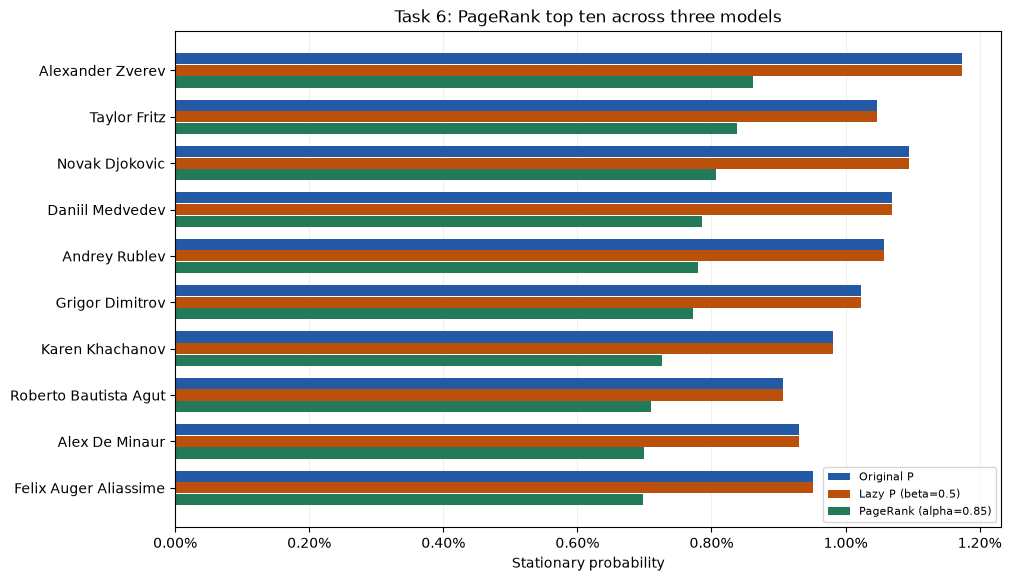

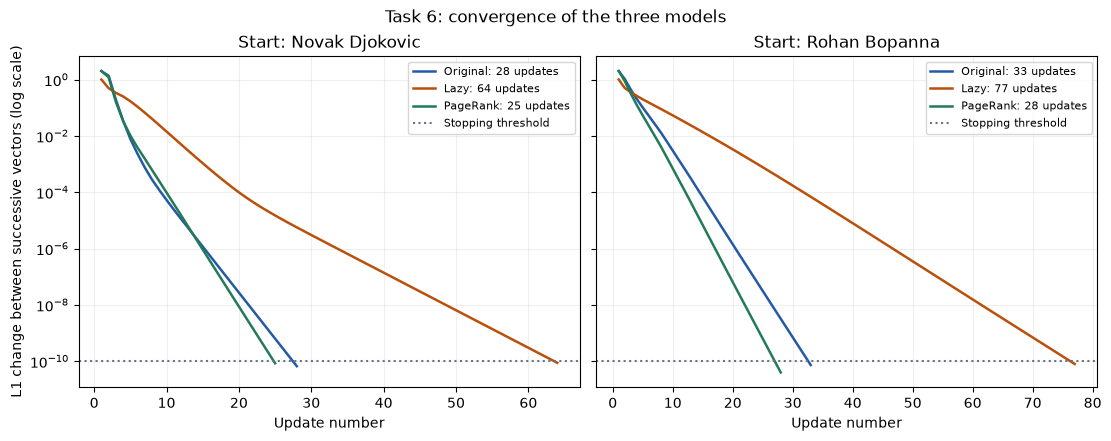

In [8]:
rows = ['| Rank | Player | Original probability | Lazy probability | PageRank probability |',
        '|---:|---|---:|---:|---:|']
for rank, i in enumerate(ranked_indices(pagerank)[:10], start=1):
    rows.append(f'| {rank} | {names_by_id[i]} | {baseline[i]:.6%} | '
                f'{lazy_scores[i]:.6%} | {pagerank[i]:.6%} |')
display(Markdown('\n'.join(rows)))
save_scores(ROOT/'data'/'task6_pagerank_scores.csv',
            baseline, lazy_scores, pagerank, names_by_id)
print('Full all-player table saved: data/task6_pagerank_scores.csv')
fig = plot_rankings(baseline, lazy_scores, pagerank, names_by_id)
fig.savefig(FIGURES/'task6_rankings.png', dpi=180)
display(fig)
plt.close(fig)
fig = plot_model_convergence(
    {'Original':original_runs, 'Lazy':lazy_runs, 'PageRank':pagerank_runs},
    'Task 6: convergence of the three models')
fig.savefig(FIGURES/'task6_convergence.png', dpi=180)
display(fig)
plt.close(fig)

### What the ranking means for tennis

PageRank stops after **25 / 28** updates, and its two final vectors differ
by about $8.16\times10^{-11}$ in $L^1$. Alexander Zverev remains first,
consistent with the team's earlier prediction, but his probability drops
from about **1.1736%** in the original walk to **0.8626%** under PageRank.
The full ranking changes, not just the leading probability: the all-node
CSV includes model-specific ranks and scores. For example, Taylor Fritz
moves from fifth to second and Djokovic from second to third. The bar chart compares the
same ten PageRank-leading players under all three models.

The $L^1$ difference between the original and PageRank score vectors is
about **0.3697**. Teleportation is not equivalent to simply mixing the final
original ranking with the uniform vector once: teleported probability then
follows match arrows in later steps. It gives weaker/less-reached nodes a
direct baseline source of mass and reduces the dominance of the top node here.

Scores describe importance in this aggregated **loser-to-winner network**,
not a definitive current skill rating. Edges ignore how many times a player
won, match recency, and score margins. Completing dangling rows and choosing
teleportation are modelling decisions. These limitations remain even though
the PageRank stationary vector is mathematically unique.

## Comparison required by the project (Tasks 5-6 scope)

| Question | Completed original P | Lazy L | PageRank G (alpha=0.85) |
|---|---|---|---|
| Row-stochastic? | Yes; zero rows already completed | Yes; convex combination with I | Yes; convex combination with uniform-row matrix |
| Power iteration on ATP data? | Converges: 28 / 33 updates | Converges: 64 / 77, slower here | Converges: 25 / 28 |
| Dependence on starting state? | No asymptotic dependence for this irreducible, aperiodic P | Same stationary set; no asymptotic dependence here | None for any initial probability vector, by positivity theorem |
| Leave a proper closed component, if one exists in the matrix? | No, by definition | No: self-loops add no exits | Yes: every destination has positive probability |
| Unique stationary ranking? | Yes for this completed ATP P, by irreducibility | Yes here because its stationary set equals P's; not guaranteed in general | Yes for every valid P with uniform teleportation and 0<alpha<1 |

Raw-graph closed components and dangling nodes must not be confused with
closed components of the **completed transition matrix**. Task 4 establishes
the completed ATP P is irreducible. Each of the three models here has no
proper closed communicating component. Laziness targets periodicity;
teleportation supplies the stronger positive-matrix guarantee.

The alpha-sensitivity sweep and its alpha-dependent figure are **Task 7**,
not implemented in this Tasks 5-6 notebook. The group must retain Task 7
in the full project submission.

In [9]:
rows = ['| Model | Start | Updates | Last L1 change | Stationary residual |',
        '|---|---|---:|---:|---:|']
for label, matrix, runs in [('Original',P,original_runs), ('Lazy',L,lazy_runs),
                             ('PageRank',G,pagerank_runs)]:
    for name, result in runs.items():
        rows.append(f'| {label} | {name} | {result.iterations} | '
                    f'{result.changes[-1]:.3e} | {stationary_residual(result.final,matrix):.3e} |')
display(Markdown('\n'.join(rows)))
assert np.array_equal(P, P_before)
print('All Task 5/6 notebook checks passed.')

| Model | Start | Updates | Last L1 change | Stationary residual |
|---|---|---:|---:|---:|
| Original | Novak Djokovic | 28 | 6.628e-11 | 3.122e-11 |
| Original | Rohan Bopanna | 33 | 7.305e-11 | 3.437e-11 |
| Lazy | Novak Djokovic | 64 | 8.751e-11 | 6.437e-11 |
| Lazy | Rohan Bopanna | 77 | 7.956e-11 | 5.838e-11 |
| PageRank | Novak Djokovic | 25 | 8.446e-11 | 3.349e-11 |
| PageRank | Rohan Bopanna | 28 | 3.984e-11 | 1.587e-11 |

All Task 5/6 notebook checks passed.


## Sources and submission integration

- IE University. *Network Centrality and PageRank Using Matrices in Python*.
  Linear Algebra and Computer Programming I group-project instructions,
  Fall 2026-2027, Tasks 5-6 and Comparison and Analysis. Blackboard,
  https://blackboard.ie.edu/ultra/courses/_161148_1/file/_3020218_1?courseId=_161148_1.
- Group project. `src/task3.py`, `src/task4.py`, original data and Tasks 1-4 notebooks.
- NumPy Developers. *NumPy Documentation*. https://numpy.org/doc/stable/.
- Matplotlib Development Team. *Matplotlib Documentation*. https://matplotlib.org/stable/.
- OpenAI. *Codex*. Assistance with Tasks 5-6 code, explanations and verification,
  26 Nov. 2026. Group review and understanding remain required.

The accompanying `report_tasks_5_6.tex` is an insertion for the group's main
report. Add it after Tasks 3-4 and upload its referenced figures to Overleaf.
It does not replace the group's 10-page main-report limit, Task 7, bibliography,
notebook sharing permissions, or submission in both courses. No slides or
submission have been generated or sent by this notebook.